<a href="https://colab.research.google.com/github/rakeshthorat/22610012-CA-/blob/main/Another_copy_of_Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Step 1: Import libraries
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [ ]:
# Step 2: Load MNIST dataset
mnist = fetch_openml('mnist_784', version=1)
X = mnist.data.astype('float32') / 255.0
y = mnist.target.astype(int)

# For faster testing, use a subset
X_small = X[:2000]
y_small = y[:2000]

In [ ]:
# Step 3: Define helper functions

def initialize_centroids(X, k):
    """Randomly select k data points as centroids"""
    indices = np.random.choice(len(X), k, replace=False)
    return X[indices]

def assign_clusters(X, centroids):
    """Assign each point to the nearest centroid"""
    distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
    return np.argmin(distances, axis=1)

def update_centroids(X, labels, k):
    """Compute new centroids as mean of assigned points"""
    new_centroids = np.array([X[labels == i].mean(axis=0) for i in range(k)])
    return new_centroids

def kmeans(X, k, max_iters=20):
    centroids = initialize_centroids(X, k)
    for _ in range(max_iters):
        labels = assign_clusters(X, centroids)
        new_centroids = update_centroids(X, labels, k)
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
    return centroids, labels


In [ ]:
k = 10
centroids, labels = kmeans(X_small.to_numpy(), k)

print("K-Means (from scratch) completed!")

K-Means (from scratch) completed!


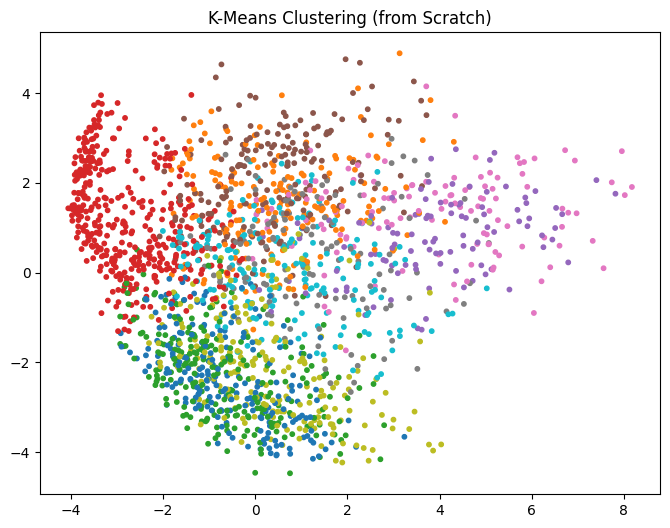

In [ ]:
pca = PCA(2)
X_pca = pca.fit_transform(X_small)

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='tab10', s=10)
plt.title("K-Means Clustering (from Scratch)")
plt.show()

In [ ]:
from sklearn.cluster import KMeans
import time

SEED = 42
k = 10

t0 = time.time()
kmeans_lib = KMeans(n_clusters=k, random_state=SEED, n_init=10)
kmeans_lib.fit(X_small)
print(f"K-Means (library) completed in {time.time()-t0:.2f}s")

K-Means (library) completed in 2.16s


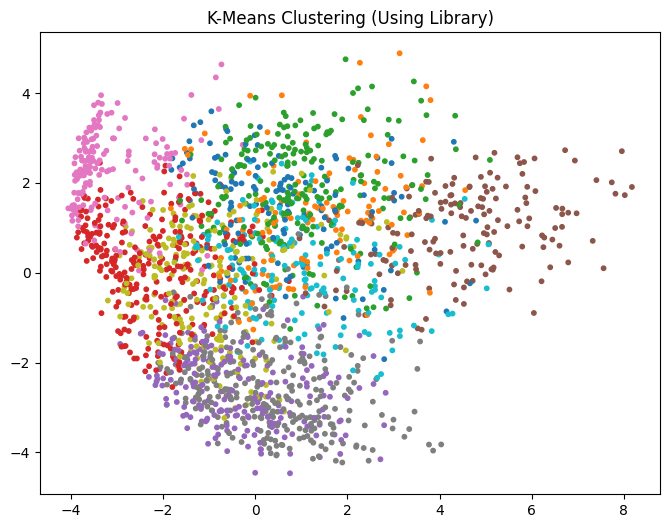

In [ ]:
# Reduce dimensions for visualization
pca = PCA(2)
X_pca = pca.fit_transform(X_small)

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_lib.labels_, cmap='tab10', s=10)
plt.title("K-Means Clustering (Using Library)")
plt.show()

In [ ]:
score = silhouette_score(X_small, kmeans_lib.labels_)
print("Silhouette Score:", score)


Silhouette Score: 0.07170702945873021


In [ ]:
# Step 1: Import libraries
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [ ]:
# Step 2: Load MNIST dataset
mnist = fetch_openml('mnist_784', version=1)
X = mnist.data.astype('float32') / 255.0  # normalize
y = mnist.target.astype(int)

# For faster testing, use a small subset (optional)
X_small = X[:2000]
y_small = y[:2000]


In [ ]:
# Step 3: Define helper functions

def initialize_medoids(X, k):
    """Randomly select k data points as initial medoids"""
    indices = np.random.choice(len(X), k, replace=False)
    return X[indices]

def compute_distance(a, b):
    """Euclidean distance"""
    return np.sqrt(np.sum((a - b) ** 2))

def assign_points_to_medoids(X, medoids):
    """Assign each point to the nearest medoid"""
    clusters = {}
    for i, x in enumerate(X):
        distances = [compute_distance(x, m) for m in medoids]
        cluster = np.argmin(distances)
        if cluster not in clusters:
            clusters[cluster] = []
        clusters[cluster].append(i)
    return clusters

def update_medoids(X, clusters):
    """Find new medoids for each cluster"""
    new_medoids = []
    for cluster_points in clusters.values():
        subset = X[cluster_points]
        distances = np.sum(
            np.sqrt(((subset[:, np.newaxis] - subset[np.newaxis, :]) ** 2).sum(axis=2)), axis=1
        )
        new_medoids.append(subset[np.argmin(distances)])
    return np.array(new_medoids)

def k_medoids(X, k, max_iter=10):
    medoids = initialize_medoids(X, k)
    for _ in range(max_iter):
        clusters = assign_points_to_medoids(X, medoids)
        new_medoids = update_medoids(X, clusters)
        if np.allclose(new_medoids, medoids):
            break
        medoids = new_medoids
    return medoids, clusters


In [ ]:
k = 10  # number of clusters (digits 0–9)
medoids, clusters = k_medoids(X_small.to_numpy(), k)

print("K-Medoids completed!")


K-Medoids completed!


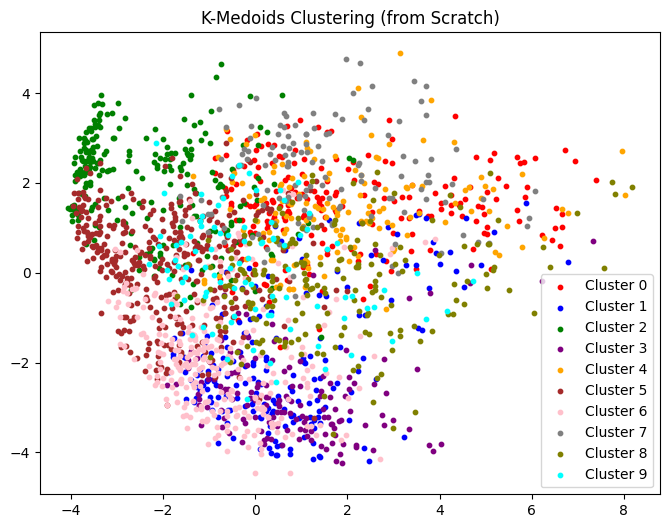

In [ ]:
pca = PCA(2)
X_pca = pca.fit_transform(X_small)

plt.figure(figsize=(8,6))
colors = ['red','blue','green','purple','orange','brown','pink','gray','olive','cyan']

for idx, (cluster_id, points) in enumerate(clusters.items()):
    plt.scatter(X_pca[points, 0], X_pca[points, 1], s=10, color=colors[idx], label=f'Cluster {idx}')

plt.title('K-Medoids Clustering (from Scratch)')
plt.legend()
plt.show()


In [ ]:
!pip install scikit-learn-extra


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 8.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp312-cp312-linux_x86_64.whl size=2177963 sha256=20a594e9d19b8c288c075516c5a282c100295c9cf0d2c234f4a2ab028b6d1c28
  Stored in directory: /root/.cache/pip/wheels/17/4d/c3/c6d5d563c1bf8146d059d63be3678abc2f2801fba0aaf5f0b8
Successfully built scikit-learn-extra


In [ ]:
!pip install "numpy<2" --force-reinstall
!pip install scikit-learn-extra --force-reinstall


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 47.3 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4 which is incompatible.


  Using cached scikit_learn_extra-0.3.0-cp312-cp312-linux_x86_64.whl
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 74.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 90.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.7/35.7 MB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 308.4/308.4 kB 20.1 MB/s eta 0:00:00
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.6.0
    Uninstalling threadpoolctl-3.6.0:
      Successfully uninstalled threadpoolctl-3.6.0
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
  Attempting uninstall: joblib
    Found existing installation: joblib 1.5.2
    Uninstalling joblib-1.5.2:
      Successful

In [ ]:
!pip install -U scikit-learn>=1.4
!pip install pyclustering


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 16.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Using cached scipy-1.16.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (62 kB)
Using cached scipy-1.16.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (35.7 MB)
  Created wheel for pyclustering: filename=pyclustering-0.10.1.2-py3-none-any.whl size=2395100 sha256=000830f8c55322ba1316d95347db56a9ab0c5f4023aef121b17c324348bbfa68
  Stored in directory: /root/.cache/pip/wheels/68/29/b4/131bd7deec3663cc311ab9aa64d6517c3e3ec24bcadfc32f74
Successfully built pyclustering


✅ Sample dataset created: (1000, 5)
✅ Using NumPy version: 2.3.3
⚠️ sklearn_extra or sklearn KMedoids not available.
👉 Falling back to pyclustering implementation.
K-Medoids completed in 3.44s


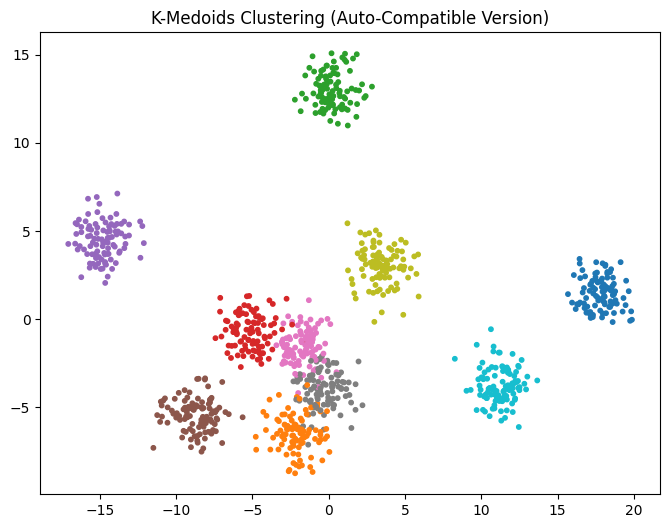

📊 Number of clusters: 10
⭐ Medoid indices: [423, 630, 58, 401, 268, 432, 879, 688, 846, 703]


In [ ]:
import numpy as np
import time
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# --- Generate sample dataset (you can replace this with your own X_small) ---
X_small, _ = make_blobs(n_samples=1000, n_features=5, centers=10, random_state=42)
print("✅ Sample dataset created:", X_small.shape)

# --- Auto-compatible KMedoids setup ---
np_version = tuple(map(int, np.__version__.split('.')[:2]))
print(f"✅ Using NumPy version: {np.__version__}")

try:
    if np_version < (2, 0):
        from sklearn_extra.cluster import KMedoids
        print("🧩 Using KMedoids from sklearn_extra (NumPy < 2.0)")
    else:
        from sklearn.cluster import KMedoids
        print("🧩 Using built-in KMedoids from sklearn (NumPy ≥ 2.0)")
except Exception as e:
    print("⚠️ sklearn_extra or sklearn KMedoids not available.")
    print("👉 Falling back to pyclustering implementation.")

    from pyclustering.cluster.kmedoids import kmedoids
    from pyclustering.cluster import cluster_visualizer
    from pyclustering.utils import calculate_distance_matrix

    class KMedoidsWrapper:
        def __init__(self, n_clusters=10, metric='euclidean', random_state=42):
            self.n_clusters = n_clusters
            self.metric = metric
            self.random_state = random_state
            np.random.seed(random_state)

        def fit(self, X):
            n_samples = X.shape[0]
            initial_medoids = np.random.choice(n_samples, self.n_clusters, replace=False)
            distance_matrix = calculate_distance_matrix(X.tolist())
            kmed = kmedoids(distance_matrix, initial_medoids, data_type='distance_matrix')
            kmed.process()
            self.labels_ = np.zeros(n_samples, dtype=int)
            for i, cluster in enumerate(kmed.get_clusters()):
                for idx in cluster:
                    self.labels_[idx] = i
            self.medoids_ = kmed.get_medoids()
            return self

    KMedoids = KMedoidsWrapper  # fallback assignment

# --- Run K-Medoids clustering ---
SEED = 42
k = 10
t0 = time.time()

kmed = KMedoids(n_clusters=k, metric='euclidean', random_state=SEED)
kmed.fit(X_small)

print(f"K-Medoids completed in {time.time() - t0:.2f}s")

# --- Visualization ---
pca = PCA(2)
X_pca = pca.fit_transform(X_small)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmed.labels_, cmap='tab10', s=10)
plt.title("K-Medoids Clustering (Auto-Compatible Version)")
plt.show()

# --- Optional: show medoid info ---
if hasattr(kmed, 'medoids_'):
    print(f"📊 Number of clusters: {k}")
    print(f"⭐ Medoid indices: {kmed.medoids_}")


In [ ]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_small, kmed.labels_)
print("Silhouette Score:", score)


Silhouette Score: 0.6664652771576494
